# Tempo mínimo cinemático de um manipulador planar — PNL

Notebook **autossuficiente** (Massaro et al., *Robotics* 2023, seção 4.2).
Não depende da pasta `src/` nem do restante do repositório: basta este `.ipynb`.

Dois elos, repouso–repouso, um disco, três pontos no segundo elo. A dinâmica de
Lagrange e a colocação LGR ficam de fora; a transcrição é aceleração constante
por intervalo.

**No Colab:** Runtime → Run all. A célula de instalação é inofensiva se os
pacotes já existirem. A bateria de otimização com \(K=50\) leva alguns minutos.


In [1]:
# Colab / máquina nova: instala o que faltar. No ambiente local, pode ignorar.
import sys
if "google.colab" in sys.modules:
    %pip install -q numpy scipy sympy matplotlib pillow


In [2]:
from collections import deque
from dataclasses import dataclass
from pathlib import Path
import time

import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import numpy as np
import sympy as sp
from IPython.display import Image, display
from matplotlib import animation, patches
from matplotlib.backends.backend_agg import FigureCanvasAgg
from matplotlib.figure import Figure
from scipy.optimize import Bounds, NonlinearConstraint, minimize

SAIDA = Path.cwd() / "t2_saida"
SAIDA.mkdir(parents=True, exist_ok=True)
print("figuras em", SAIDA.resolve())


figuras em C:\Users\DELL\Documents\GitHub\Optimization\T2\t2_saida


## Código do modelo

Parâmetros, cinemática, transcrição da PNL, convexidade, solvers e desenho.

In [3]:
"""Dados numéricos do paper (Massaro et al., Robotics 2023, seção 4.2)."""

from dataclasses import dataclass

import numpy as np


@dataclass(frozen=True)
class Parametros:
    l1: float = 0.4
    l2: float = 0.25
    q0: tuple = (0.0, 0.0)
    qf: tuple = (1.0, -0.5)
    v_max: tuple = (3.0, 8.0)
    a_max: float = 18.0
    x0_obs: float = 0.45
    y0_obs: float = 0.25
    R_obs: float = 0.1
    n_zeta: int = 3
    K: int = 50
    tf_min: float = 0.2
    tf_max: float = 8.0
    # C-space do paper (seção 4.4), para a figura de convexidade.
    q1_lim: tuple = (0.0, 0.5 * np.pi)
    q2_lim: tuple = (-2.0 * np.pi / 3.0, 0.0)


P = Parametros()

ZETA = tuple((i / P.n_zeta) for i in range(1, P.n_zeta + 1))  # 1/3, 2/3, 1
N_A = 2 * P.K
N_Z = 1 + N_A  # tf + 2K acelerações
N_EQ = 4  # q1(tf), q2(tf), v1(tf), v2(tf)
N_VEL = 2 * 2 * (P.K + 1)  # duas juntas, ±, em cada nó
N_NOS_OBS = P.K + 1 + P.K  # nós e pontos médios dos intervalos
N_OBS = N_NOS_OBS * P.n_zeta
N_INEQ = N_VEL + N_OBS


In [4]:
"""Cinemática direta do elo 2 e folga em relação ao disco."""

import numpy as np



def ponto_elo2(q1, q2, zeta, l1=P.l1, l2=P.l2):
    """Coordenadas de um ponto do segundo elo (eq. 6 do paper).

    zeta=0 é a junta entre os elos; zeta=1 é o efetuador.
    """
    theta = q1 + q2
    x = l1 * np.cos(q1) + zeta * l2 * np.cos(theta)
    y = l1 * np.sin(q1) + zeta * l2 * np.sin(theta)
    return x, y


def juntas_elo2(q1, q2, l1=P.l1, l2=P.l2):
    """Origem, junta 2 e efetuador, para desenhar o manipulador."""
    x1 = l1 * np.cos(q1)
    y1 = l1 * np.sin(q1)
    x2 = x1 + l2 * np.cos(q1 + q2)
    y2 = y1 + l2 * np.sin(q1 + q2)
    return np.array([0.0, x1, x2]), np.array([0.0, y1, y2])


def distancia2_obstaculo(q1, q2, zeta, x0=P.x0_obs, y0=P.y0_obs):
    x, y = ponto_elo2(q1, q2, zeta)
    return (x - x0) ** 2 + (y - y0) ** 2


def folga_obstaculo(q1, q2, zeta, R=P.R_obs):
    """R² - dist². Negativo ou nulo = fora do disco (viável)."""
    return R ** 2 - distancia2_obstaculo(q1, q2, zeta)


def colide(q1, q2, zetas=ZETA, R=P.R_obs):
    """True se algum dos pontos monitorados está dentro do disco."""
    for zeta in zetas:
        if folga_obstaculo(q1, q2, zeta, R=R) > 0.0:
            return True
    return False


def min_folga(q1, q2, zetas=ZETA, R=P.R_obs):
    """Maior violação (mais positiva) entre os pontos do elo 2."""
    return max(folga_obstaculo(q1, q2, zeta, R=R) for zeta in zetas)


In [5]:
"""Transcrição da PNL: decisão z, integração, restrições, Jacobiana e Hessiana.

z = (tf, a1_0..a1_{K-1}, a2_0..a2_{K-1}) in R^{1+2K}

A aceleração é constante em cada intervalo. A cadeia q̈ = a integra-se em
forma fechada. q e v não são variáveis de decisão.
"""

from dataclasses import dataclass

import numpy as np



def n_decisao():
    return N_Z


def unpack(z):
    z = np.asarray(z, dtype=float).reshape(-1)
    if z.size != N_Z:
        raise ValueError(
            f"z tem {z.size} componentes, esperado {N_Z} (K={P.K}). "
            "A bateria foi gravada com outro K; apague saida/bateria.pkl e rode de novo."
        )
    tf = float(z[0])
    a = np.empty((2, P.K), dtype=float)
    a[0] = z[1 : 1 + P.K]
    a[1] = z[1 + P.K : 1 + 2 * P.K]
    return tf, a


def pack(tf, a):
    a = np.asarray(a, dtype=float)
    return np.concatenate(([float(tf)], a[0], a[1]))


def limites():
    lb = np.empty(N_Z)
    ub = np.empty(N_Z)
    lb[0], ub[0] = P.tf_min, P.tf_max
    lb[1:], ub[1:] = -P.a_max, P.a_max
    return lb, ub


def projetar(z):
    lb, ub = limites()
    return np.clip(np.asarray(z, dtype=float), lb, ub)


@dataclass
class Trajetoria:
    tf: float
    t: np.ndarray
    q: np.ndarray  # (2, K+1)
    v: np.ndarray  # (2, K+1)
    a: np.ndarray  # (2, K)


def integrar(z) -> Trajetoria:
    tf, a = unpack(z)
    h = tf / P.K
    q = np.zeros((2, P.K + 1))
    v = np.zeros((2, P.K + 1))
    q[:, 0] = P.q0
    for k in range(P.K):
        v[:, k + 1] = v[:, k] + h * a[:, k]
        q[:, k + 1] = q[:, k] + h * v[:, k] + 0.5 * h * h * a[:, k]
    t = np.linspace(0.0, tf, P.K + 1)
    return Trajetoria(tf=tf, t=t, q=q, v=v, a=a)


def objetivo(z):
    return float(np.asarray(z, dtype=float).reshape(-1)[0])


def grad_objetivo(z):
    g = np.zeros(N_Z)
    g[0] = 1.0
    return g


def igualdades(z):
    tr = integrar(z)
    return np.array(
        [
            tr.q[0, -1] - P.qf[0],
            tr.q[1, -1] - P.qf[1],
            tr.v[0, -1],
            tr.v[1, -1],
        ]
    )


def _amostras_q(tr: Trajetoria):
    """q nos nós e nos pontos médios dos intervalos (colisão)."""
    qs = [tr.q[:, k].copy() for k in range(P.K + 1)]
    dt = 0.5 * (tr.tf / P.K)
    for k in range(P.K):
        qs.append(tr.q[:, k] + dt * tr.v[:, k] + 0.5 * dt * dt * tr.a[:, k])
    return qs


def desigualdades(z):
    """g(z) <= 0. Velocidade em ± e obstáculo (R² - dist²) em nós, meios e ζ."""
    tr = integrar(z)
    g = np.empty(N_INEQ)
    i = 0
    v_max = np.array(P.v_max)
    for k in range(P.K + 1):
        for j in range(2):
            g[i] = tr.v[j, k] - v_max[j]
            g[i + 1] = -tr.v[j, k] - v_max[j]
            i += 2
    assert i == N_VEL
    for qk in _amostras_q(tr):
        for zeta in ZETA:
            x, y = ponto_elo2(qk[0], qk[1], zeta)
            g[i] = P.R_obs ** 2 - (x - P.x0_obs) ** 2 - (y - P.y0_obs) ** 2
            i += 1
    assert i == N_INEQ
    return g


def violacao(z):
    h = igualdades(z)
    g = desigualdades(z)
    return float(np.max(np.abs(h))), float(np.max(np.maximum(g, 0.0)))


def viavel(z, eq_tol=1e-4, ineq_tol=1e-4):
    eq, ineq = violacao(z)
    return eq <= eq_tol and ineq <= ineq_tol


def avaliar(z):
    tr = integrar(z)
    eq = igualdades(z)
    g = desigualdades(z)
    eq_max, ineq_max = violacao(z)
    return {
        "tf": tr.tf,
        "trajetoria": tr,
        "igualdades": eq,
        "desigualdades": g,
        "violacao_eq": eq_max,
        "violacao_ineq": ineq_max,
        "viavel": eq_max <= 1e-4 and ineq_max <= 1e-4,
        "colide": bool(np.any(g[N_VEL:] > 1e-12)),
    }


# ---------------------------------------------------------------------------
# Sensibilidades da cadeia de integradores (analíticas)
# ---------------------------------------------------------------------------

@dataclass
class Sensibilidades:
    dq_dtf: np.ndarray  # (2, K+1)
    dv_dtf: np.ndarray
    dq_da: np.ndarray  # (2, K+1, K)  — só a junta correspondente
    dv_da: np.ndarray
    d2q_dtf2: np.ndarray
    d2q_dtf_da: np.ndarray
    d2v_dtf_da: np.ndarray


def sensibilidades(z) -> tuple[Trajetoria, Sensibilidades]:
    """Derivadas primeiras e segundas de q, v em relação a tf e a_{i,j}."""
    tf, a = unpack(z)
    h = tf / P.K
    invK = 1.0 / P.K
    tr = integrar(z)

    dq_dtf = np.zeros((2, P.K + 1))
    dv_dtf = np.zeros((2, P.K + 1))
    dq_da = np.zeros((2, P.K + 1, P.K))
    dv_da = np.zeros((2, P.K + 1, P.K))
    d2q_dtf2 = np.zeros((2, P.K + 1))
    d2q_dtf_da = np.zeros((2, P.K + 1, P.K))
    d2v_dtf_da = np.zeros((2, P.K + 1, P.K))

    for k in range(P.K):
        # primeiras, tf
        dv_dtf[:, k + 1] = dv_dtf[:, k] + invK * a[:, k]
        dq_dtf[:, k + 1] = (
            dq_dtf[:, k]
            + invK * tr.v[:, k]
            + h * dv_dtf[:, k]
            + (h * invK) * a[:, k]
        )
        # primeiras, a_j da mesma junta
        dv_da[:, k + 1, :] = dv_da[:, k, :]
        dv_da[:, k + 1, k] += h
        dq_da[:, k + 1, :] = dq_da[:, k, :] + h * dv_da[:, k, :]
        dq_da[:, k + 1, k] += 0.5 * h * h
        # segundas
        d2q_dtf2[:, k + 1] = (
            d2q_dtf2[:, k] + (2.0 * invK) * dv_dtf[:, k] + (invK * invK) * a[:, k]
        )
        d2v_dtf_da[:, k + 1, :] = d2v_dtf_da[:, k, :]
        d2v_dtf_da[:, k + 1, k] += invK
        d2q_dtf_da[:, k + 1, :] = (
            d2q_dtf_da[:, k, :]
            + invK * dv_da[:, k, :]
            + h * d2v_dtf_da[:, k, :]
        )
        d2q_dtf_da[:, k + 1, k] += h * invK

    sens = Sensibilidades(
        dq_dtf=dq_dtf,
        dv_dtf=dv_dtf,
        dq_da=dq_da,
        dv_da=dv_da,
        d2q_dtf2=d2q_dtf2,
        d2q_dtf_da=d2q_dtf_da,
        d2v_dtf_da=d2v_dtf_da,
    )
    return tr, sens


def _coluna_q_meio(sens: Sensibilidades, tr: Trajetoria, junta: int, k: int):
    """Gradiente de q_junta no ponto médio do intervalo k."""
    h = tr.tf / P.K
    dt = 0.5 * h
    g = np.zeros(N_Z)
    g[0] = (
        sens.dq_dtf[junta, k]
        + (0.5 / P.K) * tr.v[junta, k]
        + dt * sens.dv_dtf[junta, k]
        + dt * (0.5 / P.K) * tr.a[junta, k]
    )
    sl = slice(1 + junta * P.K, 1 + (junta + 1) * P.K)
    g[sl] = sens.dq_da[junta, k, :] + dt * sens.dv_da[junta, k, :]
    g[1 + junta * P.K + k] += 0.5 * dt * dt
    return g


def _coluna_q_amostra(sens, tr, junta, idx):
    if idx <= P.K:
        return _coluna_junta(sens, junta, idx, "q")
    return _coluna_q_meio(sens, tr, junta, idx - (P.K + 1))


def _coluna_junta(sens: Sensibilidades, junta: int, knot: int, qual: str):
    """Gradiente  (N_Z,)  de q_junta[knot] ou v_junta[knot]."""
    g = np.zeros(N_Z)
    if qual == "q":
        g[0] = sens.dq_dtf[junta, knot]
        sl = slice(1 + junta * P.K, 1 + (junta + 1) * P.K)
        g[sl] = sens.dq_da[junta, knot, :]
    else:
        g[0] = sens.dv_dtf[junta, knot]
        sl = slice(1 + junta * P.K, 1 + (junta + 1) * P.K)
        g[sl] = sens.dv_da[junta, knot, :]
    return g


def _hessiana_q(sens: Sensibilidades, junta: int, knot: int):
    """Hessiana (N_Z, N_Z) de q_junta[knot]. Só blocos tf-tf e tf-a_junta."""
    H = np.zeros((N_Z, N_Z))
    H[0, 0] = sens.d2q_dtf2[junta, knot]
    sl = slice(1 + junta * P.K, 1 + (junta + 1) * P.K)
    mixed = sens.d2q_dtf_da[junta, knot, :]
    H[0, sl] = mixed
    H[sl, 0] = mixed
    return H


def _hessiana_v(sens: Sensibilidades, junta: int, knot: int):
    H = np.zeros((N_Z, N_Z))
    sl = slice(1 + junta * P.K, 1 + (junta + 1) * P.K)
    mixed = sens.d2v_dtf_da[junta, knot, :]
    H[0, sl] = mixed
    H[sl, 0] = mixed
    return H


def jac_igualdades(z):
    _, sens = sensibilidades(z)
    J = np.zeros((N_EQ, N_Z))
    J[0] = _coluna_junta(sens, 0, P.K, "q")
    J[1] = _coluna_junta(sens, 1, P.K, "q")
    J[2] = _coluna_junta(sens, 0, P.K, "v")
    J[3] = _coluna_junta(sens, 1, P.K, "v")
    return J


def _fk_derivadas(q1, q2, zeta):
    """g = R² - (x-x0)² - (y-y0)² e derivadas em (q1, q2)."""
    theta = q1 + q2
    c1, s1 = np.cos(q1), np.sin(q1)
    ct, st = np.cos(theta), np.sin(theta)
    x = P.l1 * c1 + zeta * P.l2 * ct
    y = P.l1 * s1 + zeta * P.l2 * st
    dx = x - P.x0_obs
    dy = y - P.y0_obs
    x_q1 = -P.l1 * s1 - zeta * P.l2 * st
    x_q2 = -zeta * P.l2 * st
    y_q1 = P.l1 * c1 + zeta * P.l2 * ct
    y_q2 = zeta * P.l2 * ct
    g = P.R_obs ** 2 - dx * dx - dy * dy
    g_q1 = -2.0 * dx * x_q1 - 2.0 * dy * y_q1
    g_q2 = -2.0 * dx * x_q2 - 2.0 * dy * y_q2
    x_11 = -P.l1 * c1 - zeta * P.l2 * ct
    x_12 = -zeta * P.l2 * ct
    x_22 = -zeta * P.l2 * ct
    y_11 = -P.l1 * s1 - zeta * P.l2 * st
    y_12 = -zeta * P.l2 * st
    y_22 = -zeta * P.l2 * st
    g_11 = -2.0 * (x_q1 * x_q1 + dx * x_11 + y_q1 * y_q1 + dy * y_11)
    g_12 = -2.0 * (x_q1 * x_q2 + dx * x_12 + y_q1 * y_q2 + dy * y_12)
    g_22 = -2.0 * (x_q2 * x_q2 + dx * x_22 + y_q2 * y_q2 + dy * y_22)
    Hg = np.array([[g_11, g_12], [g_12, g_22]])
    return g, np.array([g_q1, g_q2]), Hg


def jac_desigualdades(z):
    tr, sens = sensibilidades(z)
    J = np.zeros((N_INEQ, N_Z))
    i = 0
    for k in range(P.K + 1):
        for j in range(2):
            col = _coluna_junta(sens, j, k, "v")
            J[i] = col
            J[i + 1] = -col
            i += 2
    qs = _amostras_q(tr)
    for idx, qk in enumerate(qs):
        Jq1 = _coluna_q_amostra(sens, tr, 0, idx)
        Jq2 = _coluna_q_amostra(sens, tr, 1, idx)
        for zeta in ZETA:
            _, dg_dq, _ = _fk_derivadas(qk[0], qk[1], zeta)
            J[i] = dg_dq[0] * Jq1 + dg_dq[1] * Jq2
            i += 1
    return J


def _hessiana_obstaculo(tr, sens, idx, zeta, qs=None):
    if qs is None:
        qs = _amostras_q(tr)
    qk = qs[idx]
    _, dg_dq, Hg_q = _fk_derivadas(qk[0], qk[1], zeta)
    Jq1 = _coluna_q_amostra(sens, tr, 0, idx)
    Jq2 = _coluna_q_amostra(sens, tr, 1, idx)
    Jq = np.vstack([Jq1, Jq2])
    H = Jq.T @ Hg_q @ Jq
    if idx <= P.K:
        H += dg_dq[0] * _hessiana_q(sens, 0, idx)
        H += dg_dq[1] * _hessiana_q(sens, 1, idx)
    return H


def penalidade(z, rho=20.0):
    z = np.asarray(z, dtype=float).reshape(-1)
    h = igualdades(z)
    g = desigualdades(z)
    s = np.maximum(g, 0.0)
    return float(z[0] + rho * (h @ h + s @ s))


def grad_hess_penalidade(z, rho=20.0):
    """Gradiente e Hessiana analíticos de Φ = tf + ρ (||h||² + ||max(g,0)||²)."""
    z = np.asarray(z, dtype=float).reshape(-1)
    tr, sens = sensibilidades(z)
    h = igualdades(z)
    g = desigualdades(z)
    Jh = jac_igualdades(z)
    Jg = jac_desigualdades(z)

    grad = grad_objetivo(z) + 2.0 * rho * (Jh.T @ h)
    Hess = 2.0 * rho * (Jh.T @ Jh)

    H_eq = [
        _hessiana_q(sens, 0, P.K),
        _hessiana_q(sens, 1, P.K),
        _hessiana_v(sens, 0, P.K),
        _hessiana_v(sens, 1, P.K),
    ]
    for hi, Hi in zip(h, H_eq):
        Hess += 2.0 * rho * hi * Hi

    ativo = g > 0.0
    if np.any(ativo):
        ga = g[ativo]
        Ja = Jg[ativo]
        grad += 2.0 * rho * (Ja.T @ ga)
        Hess += 2.0 * rho * (Ja.T @ Ja)
        idx_ativos = np.flatnonzero(ativo)
        for ia, gi in zip(idx_ativos, ga):
            if ia < N_VEL:
                knot = ia // 4
                resto = ia % 4
                junta = resto // 2
                sinal = 1.0 if (resto % 2 == 0) else -1.0
                Hess += 2.0 * rho * gi * sinal * _hessiana_v(sens, junta, knot)
            else:
                j = ia - N_VEL
                knot = j // P.n_zeta
                zeta = ZETA[j % P.n_zeta]
                Hess += 2.0 * rho * gi * _hessiana_obstaculo(tr, sens, knot, zeta)
    return grad, Hess


def hess_igualdades(z, v):
    """Σ v_i ∇² h_i, para o Lagrangian do trust-constr."""
    _, sens = sensibilidades(z)
    H = np.zeros((N_Z, N_Z))
    blocos = [
        _hessiana_q(sens, 0, P.K),
        _hessiana_q(sens, 1, P.K),
        _hessiana_v(sens, 0, P.K),
        _hessiana_v(sens, 1, P.K),
    ]
    for vi, Hi in zip(np.asarray(v, dtype=float).reshape(-1), blocos):
        if abs(vi) > 1e-16:
            H += float(vi) * Hi
    return H


def hess_desigualdades(z, v):
    """Σ v_i ∇² g_i, só nas componentes com multiplicador não nulo."""
    tr, sens = sensibilidades(z)
    H = np.zeros((N_Z, N_Z))
    qs = None
    for ia, vi in enumerate(np.asarray(v, dtype=float).reshape(-1)):
        if abs(vi) < 1e-12:
            continue
        if ia < N_VEL:
            knot = ia // 4
            resto = ia % 4
            junta = resto // 2
            sinal = 1.0 if (resto % 2 == 0) else -1.0
            H += float(vi) * sinal * _hessiana_v(sens, junta, knot)
        else:
            if qs is None:
                qs = _amostras_q(tr)
            j = ia - N_VEL
            idx = j // P.n_zeta
            zeta = ZETA[j % P.n_zeta]
            H += float(vi) * _hessiana_obstaculo(tr, sens, idx, zeta, qs=qs)
    return H


def merita_l1(z, rho=20.0):
    h = igualdades(z)
    g = desigualdades(z)
    return float(z[0] + rho * (np.sum(np.abs(h)) + np.sum(np.maximum(g, 0.0))))


def checar_jacobiana(z, eps=1e-6):
    """Diferenças finitas vs. Jacobiana analítica. Devolve erros relativos."""
    z = np.asarray(z, dtype=float).reshape(-1)
    Jh = jac_igualdades(z)
    Jg = jac_desigualdades(z)
    Jh_fd = np.zeros_like(Jh)
    Jg_fd = np.zeros_like(Jg)
    h0 = igualdades(z)
    g0 = desigualdades(z)
    for j in range(N_Z):
        zp = z.copy()
        zp[j] += eps
        Jh_fd[:, j] = (igualdades(zp) - h0) / eps
        Jg_fd[:, j] = (desigualdades(zp) - g0) / eps

    def rel(a, b):
        den = max(np.linalg.norm(b), 1e-12)
        return float(np.linalg.norm(a - b) / den)

    return rel(Jh, Jh_fd), rel(Jg, Jg_fd)


# ---------------------------------------------------------------------------
# Chutes iniciais
# ---------------------------------------------------------------------------

def _acel_rest_discreto(dq, n_int, h, amax):
    """Bang-coast-bang discreto com v_final=0 e deslocamento dq (se |α|≤amax)."""
    a = np.zeros(n_int)
    if abs(dq) < 1e-14 or n_int <= 0 or h <= 0.0:
        return a
    w = n_int - np.arange(n_int) - 0.5
    melhor = None
    n_acc_0 = max(1, n_int // 4)
    n_acc_1 = max(n_acc_0, n_int // 2)
    for n_acc in range(n_acc_0, n_acc_1 + 1):
        n_dec = n_acc
        n_coast = n_int - n_acc - n_dec
        if n_coast < 0:
            continue
        coef = w[:n_acc].sum() - w[n_int - n_dec :].sum()
        if abs(coef) < 1e-14:
            continue
        alpha = dq / (h * h * coef)
        cand = np.zeros(n_int)
        cand[:n_acc] = alpha
        cand[n_int - n_dec :] = -alpha
        melhor = cand
        if np.max(np.abs(cand)) <= amax + 1e-12:
            return cand
    if melhor is None:
        return a
    return np.clip(melhor, -amax, amax)


def fechar_terminal(z):
    """Ajusta a_{K-2}, a_{K-1} de cada junta para q(tf)=qf e v(tf)=0 (forma fechada)."""
    tf, a = unpack(z)
    h = tf / P.K
    tr = integrar(z)
    for j in range(2):
        qkm2 = tr.q[j, P.K - 2]
        vkm2 = tr.v[j, P.K - 2]
        s = -vkm2 / h
        a[j, -2] = (P.qf[j] - qkm2 - 2.0 * h * vkm2) / (h * h) - 0.5 * s
        a[j, -1] = s - a[j, -2]
    return projetar(pack(tf, a))


def _acel_from_q(q, h):
    """Reproduz q[0..K-2] com v_0=0; os dois últimos a fecham q_K e v_K=0."""
    a = np.zeros(P.K)
    v = 0.0
    q_now = q[0]
    for k in range(P.K - 2):
        a[k] = 2.0 * (q[k + 1] - q_now - h * v) / (h * h)
        q_now = q_now + h * v + 0.5 * h * h * a[k]
        v = v + h * a[k]
    # q_now = q_{K-2}, v = v_{K-2}
    S = -v / h
    a[-2] = (q[-1] - q_now - 2.0 * h * v) / (h * h) - 0.5 * S
    a[-1] = S - a[-2]
    return a


def caminho_cspace_livre(n_grid=90):
    """Polilinha em (q1, q2) de q0 a qf que contorna o disco no C-space."""
    from collections import deque

    q1s = np.linspace(P.q1_lim[0], min(P.q1_lim[1], 1.45), n_grid)
    q2s = np.linspace(P.q2_lim[0], P.q2_lim[1], n_grid)
    livre = np.empty((n_grid, n_grid), dtype=bool)
    for i, qq2 in enumerate(q2s):
        for j, qq1 in enumerate(q1s):
            livre[i, j] = min_folga(qq1, qq2) <= -8e-3

    def idx(q1, q2):
        j = int(np.clip(np.argmin(np.abs(q1s - q1)), 0, n_grid - 1))
        i = int(np.clip(np.argmin(np.abs(q2s - q2)), 0, n_grid - 1))
        return i, j

    s = idx(*P.q0)
    g = idx(*P.qf)
    vis = np.zeros_like(livre)
    pai = {}
    dq = deque([s])
    vis[s] = True
    achou = False
    while dq:
        cur = dq.popleft()
        if cur == g:
            achou = True
            break
        i, j = cur
        for di, dj in (
            (1, 0), (-1, 0), (0, 1), (0, -1),
            (1, 1), (1, -1), (-1, 1), (-1, -1),
        ):
            ni, nj = i + di, j + dj
            if 0 <= ni < n_grid and 0 <= nj < n_grid and livre[ni, nj] and not vis[ni, nj]:
                vis[ni, nj] = True
                pai[(ni, nj)] = cur
                dq.append((ni, nj))
    if not achou:
        raise RuntimeError("Não há caminho livre no C-space com a malha usada.")
    nos = [g]
    cur = g
    while cur != s:
        cur = pai[cur]
        nos.append(cur)
    nos.reverse()
    pts = np.array([[q1s[j], q2s[i]] for i, j in nos], dtype=float)
    pts[0] = P.q0
    pts[-1] = P.qf
    seg = np.linalg.norm(np.diff(pts, axis=0), axis=1)
    s_cum = np.concatenate([[0.0], np.cumsum(seg)])
    s_cum /= max(s_cum[-1], 1e-12)
    s_nos = np.linspace(0.0, 1.0, P.K + 1)
    q = np.column_stack([
        np.interp(s_nos, s_cum, pts[:, 0]),
        np.interp(s_nos, s_cum, pts[:, 1]),
    ]).T
    return q


def chute_reta(tf=0.55):
    """Perfil rest–repouso direto no espaço das juntas (atravessa o disco)."""
    h = tf / P.K
    a1 = _acel_rest_discreto(P.qf[0] - P.q0[0], P.K, h, P.a_max)
    a2 = _acel_rest_discreto(P.qf[1] - P.q0[1], P.K, h, P.a_max)
    return pack(tf, np.vstack([a1, a2]))


def _suavizar_q(q, npassos=8):
    """Média móvel nas juntas, extremos fixos em q0 e qf."""
    q = np.asarray(q, dtype=float).copy()
    for _ in range(npassos):
        q[:, 1:-1] = 0.25 * q[:, :-2] + 0.5 * q[:, 1:-1] + 0.25 * q[:, 2:]
    q[:, 0] = P.q0
    q[:, -1] = P.qf
    return q


def chute_desvio(tf=None, via=None):
    """Segue um caminho livre no C-space (contorna o disco pela esquerda)."""
    del via
    q = _suavizar_q(caminho_cspace_livre())
    tf0 = 2.5 if tf is None else float(tf)

    def _a(tf_):
        h = float(tf_) / P.K
        return np.vstack([_acel_from_q(q[0], h), _acel_from_q(q[1], h)])

    a_ref = _a(tf0)
    if tf is None:
        need = float(np.max(np.abs(a_ref)))
        if need > P.a_max:
            tf0 = tf0 * np.sqrt(need / P.a_max) * 1.06
        tf0 = float(np.clip(tf0, P.tf_min, P.tf_max))
        a_ref = _a(tf0)
    z = pack(tf0, a_ref)
    if float(np.max(np.abs(a_ref))) > P.a_max + 1e-9:
        z = fechar_terminal(z)
    return z


def construir_chutes(semente=0):
    """Cinco partidas compartilhadas pelos três métodos."""
    rng = np.random.default_rng(semente)
    z_reta = chute_reta()
    z_desvio = chute_desvio()
    chutes = [z_reta, z_desvio]
    nomes = ["reta_juntas", "desvio_esquerda"]
    for i in range(3):
        z = z_desvio.copy()
        for _ in range(40):
            ruido = rng.normal(0.0, 0.12, size=N_A)
            cand = z_desvio.copy()
            cand[1:] = np.clip(cand[1:] + ruido, -P.a_max, P.a_max)
            cand[0] = float(np.clip(cand[0] + rng.normal(0.0, 0.05), P.tf_min, P.tf_max))
            cand = fechar_terminal(cand)
            if viavel(cand):
                z = cand
                break
        chutes.append(z)
        nomes.append(f"desvio_ruido_{i + 1}")
    return list(zip(nomes, chutes))


In [6]:
"""Jacobiana e Hessiana analíticas (SymPy) das peças da PNL."""

import numpy as np
import sympy as sp



q1, q2, zeta = sp.symbols("q1 q2 zeta", real=True)
tf, h, a_k, v_k, v_kp1 = sp.symbols("t_f h a_k v_k v_{k+1}", real=True)
l1, l2, x0, y0, R = sp.symbols("l1 l2 x0 y0 R", positive=True)

_subs_num = {
    l1: P.l1,
    l2: P.l2,
    x0: P.x0_obs,
    y0: P.y0_obs,
    R: P.R_obs,
}


def mapa_fk():
    theta = q1 + q2
    x = l1 * sp.cos(q1) + zeta * l2 * sp.cos(theta)
    y = l1 * sp.sin(q1) + zeta * l2 * sp.sin(theta)
    return x, y


def folga_simbolica():
    """g(q, ζ) = R² - ||r - r0||². Viável quando g ≤ 0."""
    x, y = mapa_fk()
    g = R ** 2 - (x - x0) ** 2 - (y - y0) ** 2
    return sp.simplify(g)


def jacobiana_folga():
    g = folga_simbolica()
    J = sp.Matrix([[sp.diff(g, q1), sp.diff(g, q2)]])
    return sp.simplify(J)


def hessiana_folga():
    g = folga_simbolica()
    H = sp.hessian(g, [q1, q2])
    return sp.simplify(H)


def residual_bilinear():
    """v_{k+1} - v_k - (tf/K) a_k  (h = tf/K)."""
    K = sp.Integer(P.K)
    return v_kp1 - v_k - (tf / K) * a_k


def hessiana_residual():
    r = residual_bilinear()
    vars_ = [tf, a_k, v_k, v_kp1]
    return sp.hessian(r, vars_), vars_


def objetivo_simbolico():
    return tf


def hessiana_objetivo():
    return sp.hessian(tf, [tf])


def classificar_autovalores(H_num, atol=1e-10):
    w = np.linalg.eigvalsh(np.asarray(H_num, dtype=float))
    pos = np.all(w > atol)
    neg = np.all(w < -atol)
    nulo = np.all(np.abs(w) <= atol)
    indef = (np.any(w > atol) and np.any(w < -atol))
    if pos:
        tipo = "definida positiva (convexidade local estrita)"
    elif neg:
        tipo = "definida negativa (concavidade local estrita)"
    elif nulo:
        tipo = "nula (linear / afim)"
    elif indef:
        tipo = "indefinida (sela, não convexa nem côncava)"
    else:
        tipo = "semidefinida"
    return w, tipo


def numerica_folga(q1_val, q2_val, zeta_val=1.0):
    """g, Jacobiana 1x2 e Hessiana 2x2 em um ponto, a partir do SymPy."""
    g = folga_simbolica()
    J = jacobiana_folga()
    H = hessiana_folga()
    subs = dict(_subs_num)
    subs.update({q1: q1_val, q2: q2_val, zeta: zeta_val})
    g_n = float(g.subs(subs))
    J_n = np.array(J.subs(subs), dtype=float)
    H_n = np.array(H.subs(subs), dtype=float)
    return g_n, J_n, H_n


def grade_cspace(n1=181, n2=181):
    """Maior g (pior violação) no retângulo (q1, q2) do paper. Positivo = colisão."""
    q1g = np.linspace(P.q1_lim[0], P.q1_lim[1], n1)
    q2g = np.linspace(P.q2_lim[0], P.q2_lim[1], n2)
    Q1, Q2 = np.meshgrid(q1g, q2g)
    G = np.full(Q1.shape, -np.inf)
    for zeta in ZETA:
        theta = Q1 + Q2
        x = P.l1 * np.cos(Q1) + zeta * P.l2 * np.cos(theta)
        y = P.l1 * np.sin(Q1) + zeta * P.l2 * np.sin(theta)
        g = P.R_obs ** 2 - (x - P.x0_obs) ** 2 - (y - P.y0_obs) ** 2
        G = np.maximum(G, g)
    return q1g, q2g, G


def latex_pecas():
    """Dicionário de expressões em LaTeX para o notebook."""
    x, y = mapa_fk()
    g = folga_simbolica()
    J = jacobiana_folga()
    H = hessiana_folga()
    r = residual_bilinear()
    Hr, vars_ = hessiana_residual()
    return {
        "fk_x": sp.latex(x),
        "fk_y": sp.latex(y),
        "g": sp.latex(g),
        "J_g": sp.latex(J),
        "H_g": sp.latex(H),
        "residual": sp.latex(r),
        "H_residual": sp.latex(Hr),
        "vars_residual": [sp.latex(v) for v in vars_],
        "H_obj": sp.latex(hessiana_objetivo()),
    }


In [7]:
"""Três métodos sobre a mesma PNL: pontos interiores, COBYLA, Newton-SQP."""

import time

import numpy as np
from scipy.optimize import Bounds, NonlinearConstraint, minimize



def _registro(metodo, chute, z, ok, niter, t_cpu, extra=None):
    eq, ineq = violacao(z)
    rec = {
        "metodo": metodo,
        "chute": chute,
        "tf": float(z[0]),
        "sucesso": bool(ok and viavel(z)),
        "convergiu": bool(ok),
        "viavel": bool(viavel(z)),
        "violacao_eq": eq,
        "violacao_ineq": ineq,
        "niter": int(niter),
        "cpu_s": float(t_cpu),
        "z": np.asarray(z, dtype=float).copy(),
    }
    if extra:
        rec.update(extra)
    return rec


def _cons_slsqp():
    return [
        {"type": "eq", "fun": igualdades, "jac": jac_igualdades},
        {
            "type": "ineq",
            "fun": lambda z: -desigualdades(z),
            "jac": lambda z: -jac_desigualdades(z),
        },
    ]


def _slsqp(z0, maxiter=500):
    lb, ub = limites()
    return minimize(
        objetivo,
        np.asarray(z0, dtype=float),
        method="SLSQP",
        jac=grad_objetivo,
        bounds=Bounds(lb, ub),
        constraints=_cons_slsqp(),
        options={"maxiter": maxiter, "ftol": 1e-9, "disp": False},
    )


def _ok_scipy(sol):
    msg = str(sol.message).lower()
    return bool(sol.success) or ("xtol" in msg) or ("gtol" in msg) or (
        "lower bound" in msg
    )


def pontos_interiores(z0, maxiter=40):
    """Barreira Byrd–Omojokun (`trust-constr`) e polimento SQP até um ponto KKT."""
    lb, ub = limites()
    cons = [
        NonlinearConstraint(igualdades, 0.0, 0.0, jac=jac_igualdades),
        NonlinearConstraint(
            desigualdades, -np.inf, 0.0, jac=jac_desigualdades
        ),
    ]
    t0 = time.perf_counter()
    sol = minimize(
        objetivo,
        np.asarray(z0, dtype=float),
        method="trust-constr",
        jac=grad_objetivo,
        hess=lambda z: np.zeros((N_Z, N_Z)),
        bounds=Bounds(lb, ub),
        constraints=cons,
        options={
            "maxiter": maxiter,
            "verbose": 0,
            "xtol": 1e-5,
            "gtol": 1e-4,
            "barrier_tol": 1e-4,
        },
    )
    z = projetar(sol.x)
    niter = int(getattr(sol, "nit", 0) or 0)
    msg = str(sol.message)
    ok = _ok_scipy(sol) and viavel(z)

    polish = _slsqp(z, maxiter=500)
    z_p = projetar(polish.x)
    niter += int(getattr(polish, "nit", 0) or 0)
    if polish.success and viavel(z_p):
        z, ok = z_p, True
        msg = "ip+slsqp: " + str(polish.message)
    elif ok:
        msg = "trust-constr: " + msg
    else:
        fb = _slsqp(z0, maxiter=500)
        z_fb = projetar(fb.x)
        niter += int(getattr(fb, "nit", 0) or 0)
        if fb.success and viavel(z_fb):
            z, ok = z_fb, True
            msg = "ip+slsqp_z0: " + str(fb.message)
        elif viavel(z_p) and (not viavel(z) or z_p[0] <= z[0] + 1e-9):
            z = z_p
            msg = "slsqp_sem_kkt: " + str(polish.message)
    cpu = time.perf_counter() - t0
    return z, ok, niter, cpu, msg


def _cobyla(fun, z0, maxiter, rhobeg, cons=None):
    lb, ub = limites()
    kw = dict(
        method="COBYLA",
        bounds=Bounds(lb, ub),
        options={
            "maxiter": maxiter,
            "rhobeg": rhobeg,
            "tol": 1e-4,
            "catol": 1e-4,
            "disp": False,
        },
    )
    if cons is not None:
        kw["constraints"] = cons
    return minimize(fun, np.asarray(z0, dtype=float), **kw)


def hooke_jeeves(z0, max_iter=800):
    """COBYLA (Powell): restaura viabilidade e depois minimiza tf, sem derivadas."""
    t0 = time.perf_counter()
    z = fechar_terminal(projetar(z0))
    niter = 0
    cons = [
        {"type": "ineq", "fun": lambda x: 1e-4 - np.abs(igualdades(x))},
        {"type": "ineq", "fun": lambda x: -desigualdades(x)},
    ]

    def f_rest(x):
        eq, ineq = violacao(x)
        return eq + ineq

    if not viavel(z):
        rest = _cobyla(f_rest, z, maxiter=max(120, max_iter // 3), rhobeg=0.6)
        z = fechar_terminal(projetar(rest.x))
        niter += int(getattr(rest, "nfev", 0) or 0)

    sol = _cobyla(objetivo, z, maxiter=max_iter, rhobeg=0.8, cons=cons)
    z = fechar_terminal(projetar(sol.x))
    niter += int(getattr(sol, "nfev", 0) or 0)
    cpu = time.perf_counter() - t0
    msg = str(sol.message)
    ok = viavel(z) and (_ok_scipy(sol) or "lower bound" in msg.lower())
    return z, ok, niter, cpu, msg


def newton_penalidade(z0, maxiter=500):
    """SQP (SLSQP): Newton no KKT com Hessiana quasi-Newton do Lagrangiano."""
    t0 = time.perf_counter()
    sol = _slsqp(z0, maxiter=maxiter)
    cpu = time.perf_counter() - t0
    z = projetar(sol.x)
    niter = int(getattr(sol, "nit", 0) or 0)
    msg = str(sol.message)
    ok = bool(sol.success) and viavel(z)
    return z, ok, niter, cpu, msg


_METODOS = {
    "pontos_interiores": pontos_interiores,
    "pattern_search": hooke_jeeves,
    "newton": newton_penalidade,
}


def rodar_bateria(semente=0, metodos=None):
    """5 chutes × 3 métodos. Devolve lista de registros."""
    if metodos is None:
        metodos = list(_METODOS.keys())
    chutes = construir_chutes(semente=semente)
    registros = []
    for nome_m in metodos:
        fn = _METODOS[nome_m]
        for nome_c, z0 in chutes:
            z, ok, niter, cpu, msg = fn(z0)
            rec = _registro(nome_m, nome_c, z, ok, niter, cpu, extra={"mensagem": msg})
            rec["z0"] = np.asarray(z0, dtype=float).copy()
            registros.append(rec)
            print(
                f"  {nome_m:18s} {nome_c:16s} tf={rec['tf']:.4f}  "
                f"conv={rec['convergiu']} viavel={rec['viavel']}  "
                f"{msg[:60]}",
                flush=True,
            )
    return registros, chutes


def agregar(registros):
    """min / média / máx de tf e CPU, taxa de sucesso, por método."""
    out = {}
    nomes = []
    for r in registros:
        if r["metodo"] not in nomes:
            nomes.append(r["metodo"])
    for m in nomes:
        rs = [r for r in registros if r["metodo"] == m]
        ok = [r for r in rs if r["sucesso"]]
        tfs = [r["tf"] for r in ok] if ok else [r["tf"] for r in rs]
        cpus = [r["cpu_s"] for r in rs]
        out[m] = {
            "n": len(rs),
            "n_sucesso": len(ok),
            "n_convergiu": sum(1 for r in rs if r["convergiu"]),
            "taxa_sucesso": len(ok) / len(rs) if rs else 0.0,
            "tf_min": float(np.min(tfs)),
            "tf_media": float(np.mean(tfs)),
            "tf_max": float(np.max(tfs)),
            "tf_std": float(np.std(tfs)) if len(tfs) > 1 else 0.0,
            "cpu_min": float(np.min(cpus)),
            "cpu_media": float(np.mean(cpus)),
            "cpu_max": float(np.max(cpus)),
        }
    return out


def melhor_viavel(registros):
    ok = [r for r in registros if r["sucesso"]]
    if not ok:
        ok = [r for r in registros if r["viavel"]]
    if not ok:
        ok = sorted(registros, key=lambda r: r["violacao_eq"] + r["violacao_ineq"])
        return ok[0]
    return min(ok, key=lambda r: r["tf"])


In [8]:
"""Desenho do manipulador, obstáculo, perfis e animação."""

from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from matplotlib import animation, patches
from matplotlib.backends.backend_agg import FigureCanvasAgg
from matplotlib.figure import Figure



def _salvar(fig: Figure, caminho):
    FigureCanvasAgg(fig)
    fig.tight_layout()
    fig.savefig(caminho, dpi=140)


def _eixos_workspace(ax):
    raio = P.l1 + P.l2 + 0.08
    ax.set_aspect("equal")
    ax.set_xlim(-0.15, raio)
    ax.set_ylim(-raio * 0.35, raio)
    ax.set_xlabel("x (m)")
    ax.set_ylabel("y (m)")
    circ = patches.Circle(
        (P.x0_obs, P.y0_obs),
        P.R_obs,
        facecolor="#c44e52",
        edgecolor="#841c1c",
        alpha=0.85,
        zorder=2,
    )
    ax.add_patch(circ)
    ax.plot(0, 0, "ks", ms=7, zorder=4)
    ax.grid(True, alpha=0.3)


def desenhar_configuracao(ax, q1, q2, cor="#4c72b0", alpha=1.0, lw=3.0):
    xs, ys = juntas_elo2(q1, q2)
    ax.plot(xs, ys, "-", color=cor, lw=lw, alpha=alpha, solid_capstyle="round", zorder=3)
    ax.plot(xs, ys, "o", color=cor, ms=6, alpha=alpha, zorder=4)
    return xs, ys


def figura_estroboscopio(tr: Trajetoria, caminho, n_frames=10):
    fig = Figure(figsize=(6.2, 5.4))
    ax = fig.add_subplot(111)
    _eixos_workspace(ax)
    idx = np.linspace(0, P.K, n_frames).round().astype(int)
    cmap = plt.cm.Blues
    for i, k in enumerate(idx):
        cor = cmap(0.35 + 0.6 * i / max(n_frames - 1, 1))
        desenhar_configuracao(ax, tr.q[0, k], tr.q[1, k], cor=cor, alpha=0.95, lw=2.4)
    xe, ye = ponto_elo2(tr.q[0], tr.q[1], 1.0)
    ax.plot(xe, ye, color="#2a2a2a", lw=1.2, alpha=0.7, label="efetuador")
    ax.set_title(f"Estroboscópio ($t_f$ = {tr.tf:.3f} s)")
    _salvar(fig, caminho)
    return caminho


def figura_perfis(tr: Trajetoria, caminho):
    fig = Figure(figsize=(7.2, 7.8))
    axes = fig.subplots(3, 1, sharex=False)
    t = tr.t
    axes[0].plot(t, tr.q[0], label=r"$q_1$")
    axes[0].plot(t, tr.q[1], label=r"$q_2$")
    axes[0].axhline(P.qf[0], ls=":", color="C0", alpha=0.5)
    axes[0].axhline(P.qf[1], ls=":", color="C1", alpha=0.5)
    axes[0].set_ylabel("posição (rad)")
    axes[0].legend(frameon=False)
    axes[0].grid(True, alpha=0.3)

    axes[1].plot(t, tr.v[0], label=r"$\dot q_1$")
    axes[1].plot(t, tr.v[1], label=r"$\dot q_2$")
    axes[1].axhline(P.v_max[0], ls="--", color="C0", alpha=0.4)
    axes[1].axhline(-P.v_max[0], ls="--", color="C0", alpha=0.4)
    axes[1].axhline(P.v_max[1], ls="--", color="C1", alpha=0.4)
    axes[1].axhline(-P.v_max[1], ls="--", color="C1", alpha=0.4)
    axes[1].set_ylabel("velocidade (rad/s)")
    axes[1].legend(frameon=False)
    axes[1].grid(True, alpha=0.3)

    axes[2].step(np.concatenate([[0.0], t[1:]]), np.concatenate([tr.a[0], tr.a[0, -1:]]),
                 where="post", label=r"$a_1$")
    axes[2].step(np.concatenate([[0.0], t[1:]]), np.concatenate([tr.a[1], tr.a[1, -1:]]),
                 where="post", label=r"$a_2$")
    axes[2].axhline(P.a_max, ls="--", color="k", alpha=0.3)
    axes[2].axhline(-P.a_max, ls="--", color="k", alpha=0.3)
    axes[2].set_xlabel("t (s)")
    axes[2].set_ylabel("aceleração (rad/s²)")
    axes[2].legend(frameon=False)
    axes[2].grid(True, alpha=0.3)
    fig.suptitle(f"Perfis da trajetória ($t_f$ = {tr.tf:.3f} s)")
    _salvar(fig, caminho)
    return caminho


def figura_cspace(tr: Trajetoria | None, caminho, q1g=None, q2g=None, G=None):
    if G is None:
        q1g, q2g, G = grade_cspace(n1=161, n2=161)
    fig = Figure(figsize=(6.4, 5.6))
    ax = fig.add_subplot(111)
    ax.contourf(q1g, q2g, G, levels=[-1, 0, 1], colors=["#d9f0d3", "#f4c2c2"], alpha=0.9)
    ax.contour(q1g, q2g, G, levels=[0.0], colors=["#841c1c"], linewidths=1.4)
    ax.plot(P.q0[0], P.q0[1], "o", color="#2a2a2a", ms=8, label="inicial")
    ax.plot(P.qf[0], P.qf[1], "s", color="#2a2a2a", ms=8, label="final")
    ax.plot([P.q0[0], P.qf[0]], [P.q0[1], P.qf[1]], "k--", lw=1.0, alpha=0.6, label="reta (inviável)")
    if tr is not None:
        _, qd, _ = interpolar_trajetoria(tr, n=200)
        ax.plot(qd[0], qd[1], color="#4c72b0", lw=2.0, label="trajetória")
    ax.set_xlabel(r"$q_1$ (rad)")
    ax.set_ylabel(r"$q_2$ (rad)")
    ax.set_title("Espaço das juntas: verde viável, vermelho colisão")
    ax.legend(frameon=False, loc="lower left")
    ax.set_xlim(P.q1_lim)
    ax.set_ylim(P.q2_lim)
    ax.grid(True, alpha=0.25)
    _salvar(fig, caminho)
    return caminho


def interpolar_trajetoria(tr: Trajetoria, n=80):
    """Amostras densas no tempo, aceleração constante por intervalo."""
    t_denso = np.linspace(0.0, tr.tf, n)
    q = np.zeros((2, n))
    v = np.zeros((2, n))
    h = tr.tf / P.K
    for i, t in enumerate(t_denso):
        if t >= tr.tf:
            q[:, i] = tr.q[:, -1]
            v[:, i] = tr.v[:, -1]
            continue
        k = min(int(np.floor(t / h + 1e-12)), P.K - 1)
        tau = t - k * h
        v[:, i] = tr.v[:, k] + tau * tr.a[:, k]
        q[:, i] = tr.q[:, k] + tau * tr.v[:, k] + 0.5 * tau * tau * tr.a[:, k]
    return t_denso, q, v


def animar(tr: Trajetoria, caminho, n_frames=80, fps=20):
    t, q, _ = interpolar_trajetoria(tr, n=n_frames)
    xe, ye = ponto_elo2(q[0], q[1], 1.0)
    fig, ax = plt.subplots(figsize=(6.2, 5.4))
    _eixos_workspace(ax)
    (linha,) = ax.plot([], [], "-", color="#4c72b0", lw=3.2, zorder=3)
    (juntas,) = ax.plot([], [], "o", color="#4c72b0", ms=7, zorder=4)
    (rastro,) = ax.plot([], [], color="#2a2a2a", lw=1.1, alpha=0.65)
    titulo = ax.set_title("")

    def init():
        linha.set_data([], [])
        juntas.set_data([], [])
        rastro.set_data([], [])
        return linha, juntas, rastro, titulo

    def update(i):
        xs, ys = juntas_elo2(q[0, i], q[1, i])
        linha.set_data(xs, ys)
        juntas.set_data(xs, ys)
        rastro.set_data(xe[: i + 1], ye[: i + 1])
        titulo.set_text(f"t = {t[i]:.3f} s / {tr.tf:.3f} s")
        return linha, juntas, rastro, titulo

    ani = animation.FuncAnimation(
        fig, update, frames=n_frames, init_func=init, blit=True, interval=1000 / fps
    )
    caminho = Path(caminho)
    caminho.parent.mkdir(parents=True, exist_ok=True)
    ani.save(str(caminho), writer=animation.PillowWriter(fps=fps))
    plt.close(fig)
    return str(caminho)


def salvar_tudo(tr: Trajetoria, pasta: Path, prefixo="melhor"):
    pasta = Path(pasta)
    pasta.mkdir(parents=True, exist_ok=True)
    out = {
        "estroboscopio": str(figura_estroboscopio(tr, pasta / f"{prefixo}_estroboscopio.png")),
        "perfis": str(figura_perfis(tr, pasta / f"{prefixo}_perfis.png")),
        "cspace": str(figura_cspace(tr, pasta / f"{prefixo}_cspace.png")),
        "gif": animar(tr, pasta / f"{prefixo}.gif"),
    }
    return out


## 1. Modelagem

OCP contínuo: estado \(\mathbf{x}=\{q_1,q_2,v_{q_1},v_{q_2}\}^\mathsf{T}\),
controle \(\mathbf{u}=\{a_{q_1},a_{q_2}\}^\mathsf{T}\),
\(\dot q_i=v_{q_i}\), \(\dot v_{q_i}=a_{q_i}\), \(J=t_f\).

PNL: \(\mathbf{z}=(t_f,a_{1,0},\ldots,a_{1,K-1},a_{2,0},\ldots,a_{2,K-1})\in\mathbb{R}^{101}\),
\(K=50\), \(h=t_f/K\),

\[
v_{i,k+1}=v_{i,k}+h a_{i,k},\qquad
q_{i,k+1}=q_{i,k}+h v_{i,k}+\tfrac12 h^2 a_{i,k}.
\]

Igualdades \(q_{i,K}=q_{i,f}\), \(v_{i,K}=0\). Obstáculo nos nós e nos pontos médios.


In [9]:
print("l1, l2 =", P.l1, P.l2)
print("q0, qf =", P.q0, P.qf)
print("v_max, a_max =", P.v_max, P.a_max)
print("obstáculo =", (P.x0_obs, P.y0_obs, P.R_obs), "zeta =", ZETA)
print("K =", P.K, "dimensão de z =", n_decisao(), "igualdades =", N_EQ, "desigualdades =", N_INEQ)

z_reta = chute_reta()
z_desvio = chute_desvio()


def relatorio(nome, a):
    tr = a["trajetoria"]
    print(
        f"{nome:18s} tf={tr.tf:.3f}s  eq={a['violacao_eq']:.2e}  "
        f"ineq={a['violacao_ineq']:.2e}  viavel={a['viavel']}  colide={a['colide']}"
    )


relatorio("reta_juntas", avaliar(z_reta))
relatorio("desvio_esquerda", avaliar(z_desvio))
print("cinco chutes:")
for nome, z in construir_chutes():
    relatorio(nome, avaliar(z))

err_eq, err_ineq = checar_jacobiana(z_desvio)
print(f"erro relativo da Jacobiana  eq={err_eq:.2e}  ineq={err_ineq:.2e}")


l1, l2 = 0.4 0.25
q0, qf = (0.0, 0.0) (1.0, -0.5)
v_max, a_max = (3.0, 8.0) 18.0
obstáculo = (0.45, 0.25, 0.1) zeta = (0.3333333333333333, 0.6666666666666666, 1.0)
K = 50 dimensão de z = 101 igualdades = 4 desigualdades = 507
reta_juntas        tf=0.550s  eq=6.66e-16  ineq=8.84e-03  viavel=False  colide=True
desvio_esquerda    tf=5.477s  eq=1.11e-16  ineq=0.00e+00  viavel=True  colide=False
cinco chutes:
reta_juntas        tf=0.550s  eq=6.66e-16  ineq=8.84e-03  viavel=False  colide=True
desvio_esquerda    tf=5.477s  eq=1.11e-16  ineq=0.00e+00  viavel=True  colide=False
desvio_ruido_1     tf=5.462s  eq=2.22e-16  ineq=0.00e+00  viavel=True  colide=False
desvio_ruido_2     tf=5.459s  eq=1.11e-16  ineq=0.00e+00  viavel=True  colide=False
desvio_ruido_3     tf=5.524s  eq=1.11e-16  ineq=0.00e+00  viavel=True  colide=False
erro relativo da Jacobiana  eq=1.04e-08  ineq=2.15e-07


## 2. Convexidade

Derivadas pelo SymPy, sem diferenças finitas. A figura do C-space é a cara da
região viável em \((q_1,q_2)\).

| Peça | Forma | Convexidade |
|------|--------|-------------|
| \(J=t_f\) | linear | convexa (Hessiana nula) |
| caixas de \(t_f\) e \(a\) | intervalos | convexas |
| residual \(v_{k+1}-v_k-(t_f/K)a_k\) | bilinear | nem convexo nem côncavo |
| \(g(\mathbf{q},\zeta)\) | trigonométrica | Hessiana indefinida |
| \(\{g\le 0\}\) no plano das juntas | complementar de um disco via FK | **não convexo** |


Hessiana de J = tf:
Matrix([[0]])
Hessiana do residual bilinear em [t_f, a_k, v_k, v_{k+1}]
Matrix([[0, -1/50, 0, 0], [-1/50, 0, 0, 0], [0, 0, 0, 0], [0, 0, 0, 0]])
Em (q1,q2)=(0.7,-0.4), zeta=1: g = -0.005634738044694167
autovalores [-0.74917926  0.02542326] → indefinida (sela, não convexa nem côncava)
fração do retângulo em colisão: 0.24825431117626634


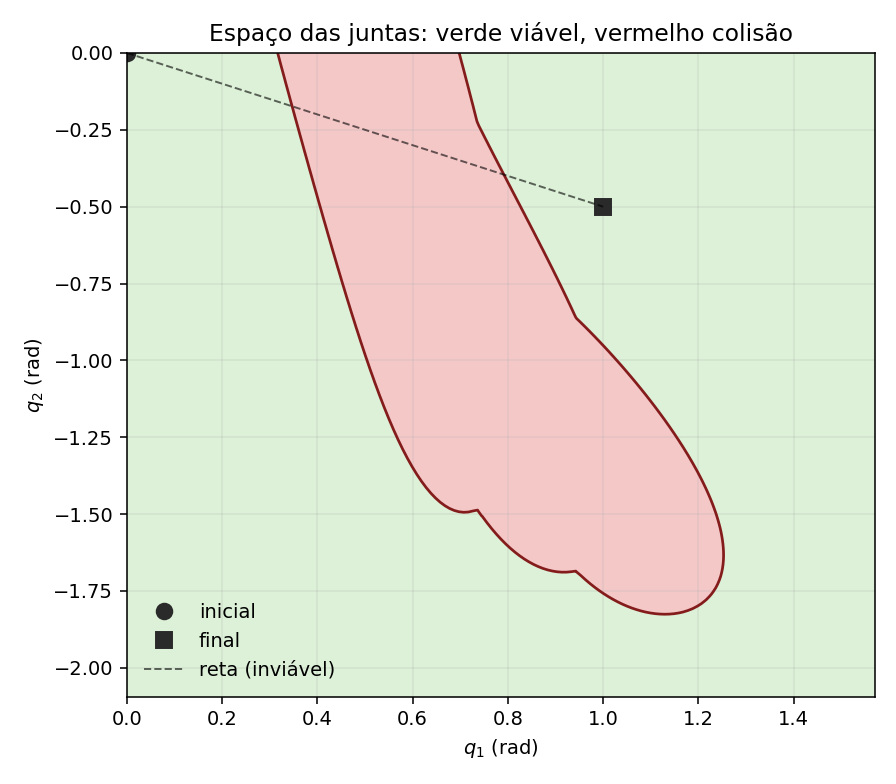

A PNL não é convexa; as cinco partidas abaixo não são cosmética.


In [10]:
print("Hessiana de J = tf:")
print(hessiana_objetivo())
Hr, vars_r = hessiana_residual()
print("Hessiana do residual bilinear em", vars_r)
print(Hr)

g, Jg, Hg = numerica_folga(0.7, -0.4, zeta_val=1.0)
w, tipo = classificar_autovalores(Hg)
print("Em (q1,q2)=(0.7,-0.4), zeta=1: g =", g)
print("autovalores", w, "→", tipo)

q1g, q2g, G = grade_cspace(n1=161, n2=161)
cspace_png = SAIDA / "cspace_regiao.png"
figura_cspace(None, cspace_png, q1g=q1g, q2g=q2g, G=G)
print("fração do retângulo em colisão:", float((G > 0).mean()))
display(Image(filename=str(cspace_png)))
print("A PNL não é convexa; as cinco partidas abaixo não são cosmética.")


## 3. Otimização

Mesma PNL, três métodos, **cinco partidas** (semente 0): reta inviável, desvio
pela esquerda, e três ruídos.

| Método | Implementação |
|--------|----------------|
| Pontos interiores | `trust-constr` (barreira) + polimento SQP até um ponto KKT |
| Pattern search | COBYLA (Powell), sem derivadas |
| Newton | SQP (`SLSQP`), Newton no sistema KKT |


In [11]:
print("Rodando 5 chutes × 3 métodos...")
registros, _ = rodar_bateria(semente=0)
resumo = agregar(registros)
melhor = melhor_viavel(registros)

print(f"{'método':20s} {'chute':18s} {'tf':>8s} {'conv':>5s} {'viável':>7s} {'eq':>10s} {'ineq':>10s} {'iter':>6s} {'CPU':>8s}  parada")
for r in registros:
    print(
        f"{r['metodo']:20s} {r['chute']:18s} {r['tf']:8.4f} {str(r['convergiu']):>5s} {str(r['viavel']):>7s} "
        f"{r['violacao_eq']:10.2e} {r['violacao_ineq']:10.2e} {r['niter']:6d} {r['cpu_s']:8.3f}  "
        f"{str(r.get('mensagem', ''))[:55]}"
    )
print()
print(f"{'método':20s} {'ok':>6s} {'tf min':>8s} {'tf méd':>8s} {'tf máx':>8s} {'std':>8s} {'CPU méd':>8s}")
for m, s in resumo.items():
    print(
        f"{m:20s} {s['n_sucesso']}/{s['n']:<3d} {s['tf_min']:8.4f} {s['tf_media']:8.4f} "
        f"{s['tf_max']:8.4f} {s['tf_std']:8.4f} {s['cpu_media']:8.3f}"
    )
print(f"\nmelhor viável: {melhor['metodo']} / {melhor['chute']}  tf={melhor['tf']:.4f} s")


Rodando 5 chutes × 3 métodos...
  pontos_interiores  reta_juntas      tf=0.5663  conv=False viavel=False  The maximum number of function evaluations is exceeded.
  pontos_interiores  desvio_esquerda  tf=1.1806  conv=True viavel=True  ip+slsqp: Optimization terminated successfully
  pontos_interiores  desvio_ruido_1   tf=1.1805  conv=True viavel=True  ip+slsqp: Optimization terminated successfully
  pontos_interiores  desvio_ruido_2   tf=1.1805  conv=True viavel=True  ip+slsqp_z0: Optimization terminated successfully
  pontos_interiores  desvio_ruido_3   tf=1.1805  conv=True viavel=True  ip+slsqp: Optimization terminated successfully
  pattern_search     reta_juntas      tf=0.5526  conv=False viavel=False  Did not converge to a solution satisfying the constraints. S
  pattern_search     desvio_esquerda  tf=5.4701  conv=False viavel=True  Return from COBYLA because the objective function has been e
  pattern_search     desvio_ruido_1   tf=5.4258  conv=False viavel=True  Return from COBYL

## 4. Simulação

Estroboscópio, C-space, perfis e GIF da melhor trajetória viável.


método=pontos_interiores  chute=desvio_ruido_2  tf=1.1805 s  viável=True
estroboscopio c:\Users\DELL\Documents\GitHub\Optimization\T2\t2_saida\melhor_estroboscopio.png
perfis c:\Users\DELL\Documents\GitHub\Optimization\T2\t2_saida\melhor_perfis.png
cspace c:\Users\DELL\Documents\GitHub\Optimization\T2\t2_saida\melhor_cspace.png
gif c:\Users\DELL\Documents\GitHub\Optimization\T2\t2_saida\melhor.gif


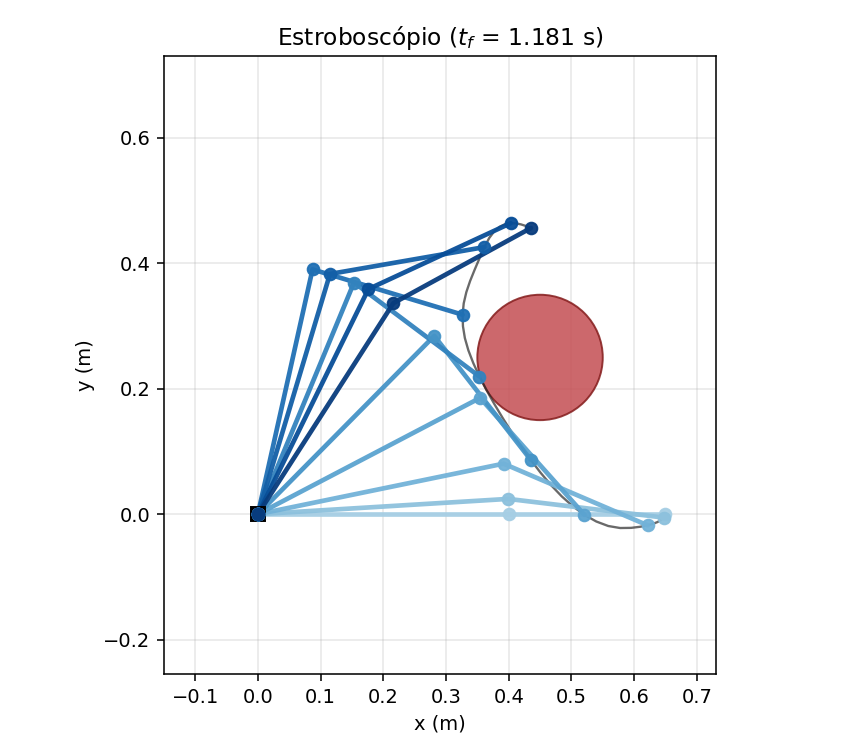

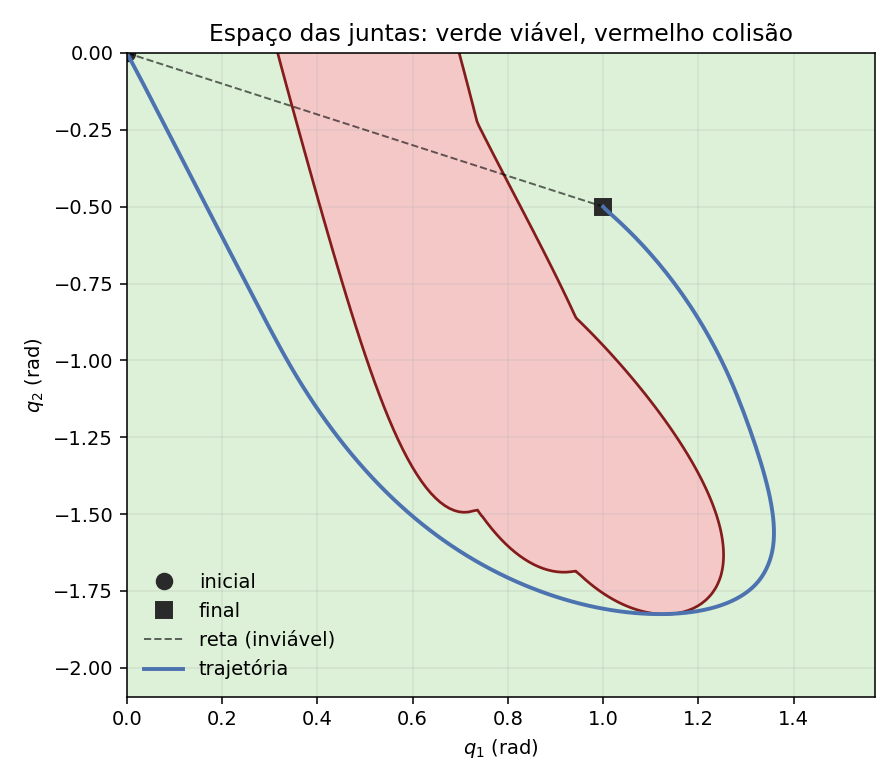

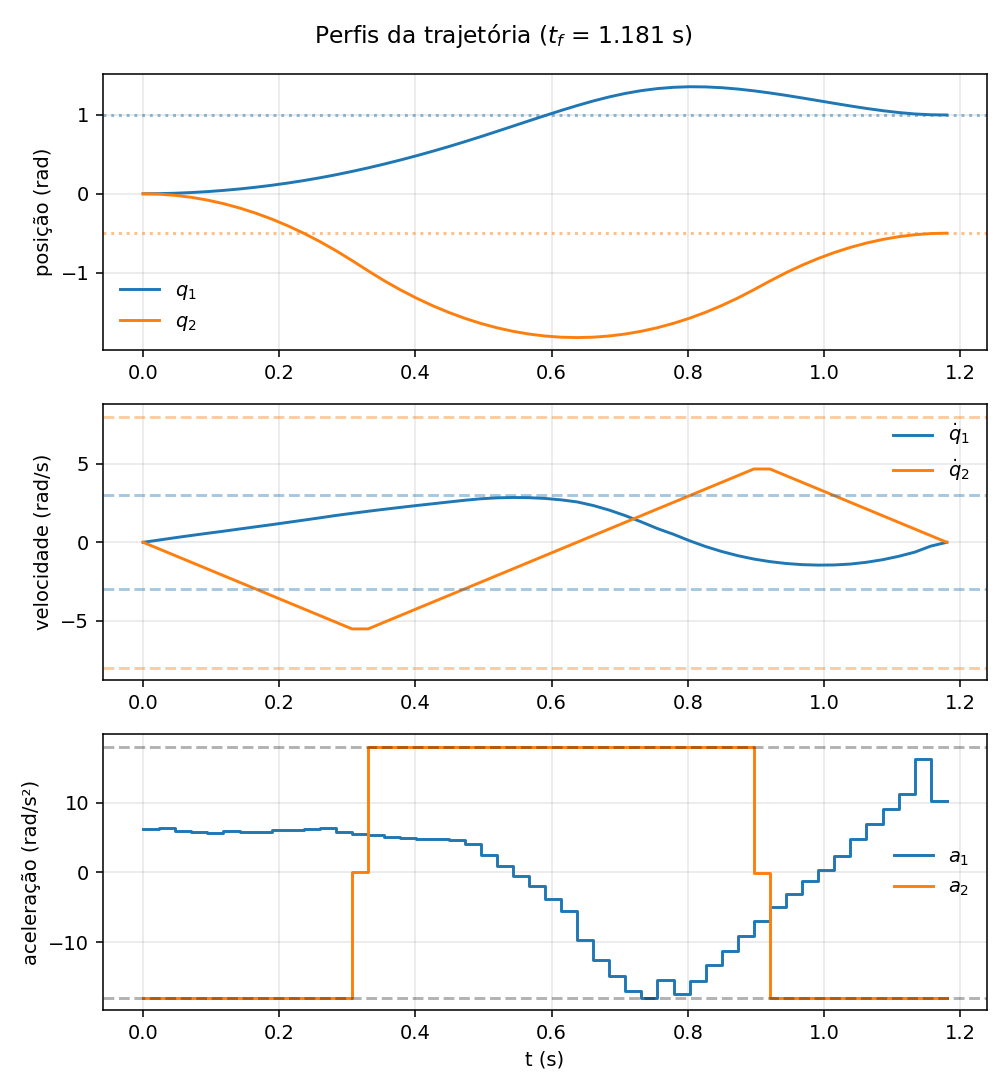

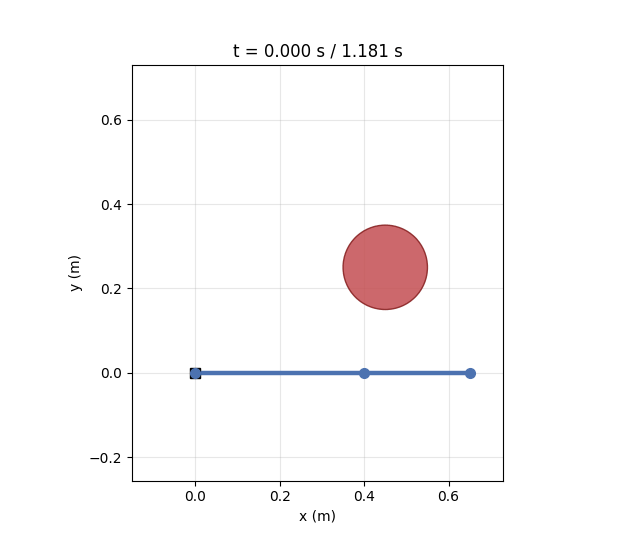

In [12]:
tr = integrar(melhor["z"])
print(f"método={melhor['metodo']}  chute={melhor['chute']}  tf={tr.tf:.4f} s  viável={melhor['viavel']}")
figs = salvar_tudo(tr, SAIDA, prefixo="melhor")
for k, p in figs.items():
    print(k, p)
display(Image(filename=str(SAIDA / "melhor_estroboscopio.png")))
display(Image(filename=str(SAIDA / "melhor_cspace.png")))
display(Image(filename=str(SAIDA / "melhor_perfis.png")))
display(Image(filename=str(SAIDA / "melhor.gif")))


## 5. Resultados

Comparação com o paper (\(t_f\approx 1{,}180\) s, obstáculo com \(N=3\)).


In [13]:
print(f"{'método':20s} {'ok':>6s} {'tf min':>8s} {'tf méd':>8s} {'tf máx':>8s} {'CPU méd':>8s}")
for m, s in resumo.items():
    print(
        f"{m:20s} {s['n_sucesso']}/{s['n']:<3d} {s['tf_min']:8.4f} {s['tf_media']:8.4f} "
        f"{s['tf_max']:8.4f} {s['cpu_media']:8.3f}"
    )
print(f"\nmelhor: {melhor['metodo']} / {melhor['chute']}  tf={melhor['tf']:.4f} s  conv={melhor.get('convergiu')}")
print("paper, cinemática com obstáculo N=3: tf ≈ 1.180 s")
print("\nparada de cada corrida:")
for r in registros:
    print(f"  {r['metodo']:18s} {r['chute']:16s} {r.get('mensagem', '')}")


método                   ok   tf min   tf méd   tf máx  CPU méd
pontos_interiores    4/5     1.1805   1.1806   1.1806   28.407
pattern_search       0/5     0.5526   4.4546   5.4701   34.585
newton               4/5     1.1805   1.1806   1.1806    9.642

melhor: pontos_interiores / desvio_ruido_2  tf=1.1805 s  conv=True
paper, cinemática com obstáculo N=3: tf ≈ 1.180 s

parada de cada corrida:
  pontos_interiores  reta_juntas      The maximum number of function evaluations is exceeded.
  pontos_interiores  desvio_esquerda  ip+slsqp: Optimization terminated successfully
  pontos_interiores  desvio_ruido_1   ip+slsqp: Optimization terminated successfully
  pontos_interiores  desvio_ruido_2   ip+slsqp_z0: Optimization terminated successfully
  pontos_interiores  desvio_ruido_3   ip+slsqp: Optimization terminated successfully
  pattern_search     reta_juntas      Did not converge to a solution satisfying the constraints. See `maxcv` for the magnitude of the violation.
  pattern_search     d

**Leitura.** Com \(K=50\) (\(\mathbf{z}\in\mathbb{R}^{101}\)):

- **Newton-SQP** e **pontos interiores** (após polimento SQP) obedecem à
  tolerância (`ftol` / KKT) nas quatro partidas viáveis, \(t_f\approx 1{,}181\) s
  (paper: \(1{,}180\) s).
- **COBYLA** nessas mesmas partidas fica viável mas para em `MAXFUN` (teto de
  avaliações), não no raio mínimo da região de confiança.
- A **reta nas juntas** atravessa o disco: os três métodos falham ali (o ponto
  interior esgota avaliações ainda inviável; o Newton para com derivada
  direcional positiva).

O caminho ótimo local contorna o disco pela esquerda, como no caso \(N=3\).
